In [1]:
import numpy as np
import os
import json
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

In [2]:
buf_fp32_scores = np.load(os.path.join('collected_outputs_nano', 'fp32_scores.npy'))
buf_fp32_boxes = np.load(os.path.join('collected_outputs_nano', 'fp32_boxes.npy'))
buf_uint8_scores = np.load(os.path.join('collected_outputs_nano', 'uint8_scores.npy'))
buf_uint8_boxes = np.load(os.path.join('collected_outputs_nano', 'uint8_boxes.npy'))

buf_fp32_scores.shape, buf_fp32_boxes.shape, buf_uint8_scores.shape, buf_uint8_boxes.shape

((4662, 1), (4662, 6), (4662, 1), (4662, 6))

(0.17082952, 0.15063342, 0.12966406, 0.8515625)

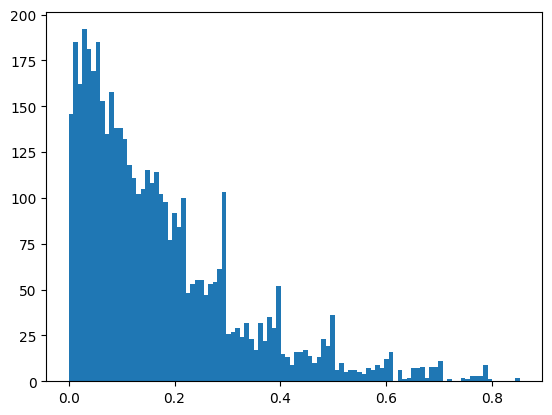

In [3]:
scores_dif = np.abs(buf_fp32_scores - buf_uint8_scores).flatten()
plt.hist(scores_dif, bins=100);
scores_dif.mean(), scores_dif.std(), np.median(scores_dif), scores_dif.max()

Coord dif mean: [5.690224  6.113868  8.985403  9.515766  5.0547137 4.986539 ]
Coord dif std: [5.225744  5.372442  6.8698277 7.4090023 3.9512916 3.4288106]
Coord dif median: [4.783596  5.0242844 7.325157  7.717249  4.358444  4.492653 ]
Coord dif max: [61.356163 76.757645 55.813168 76.60806  65.52607  33.006355]


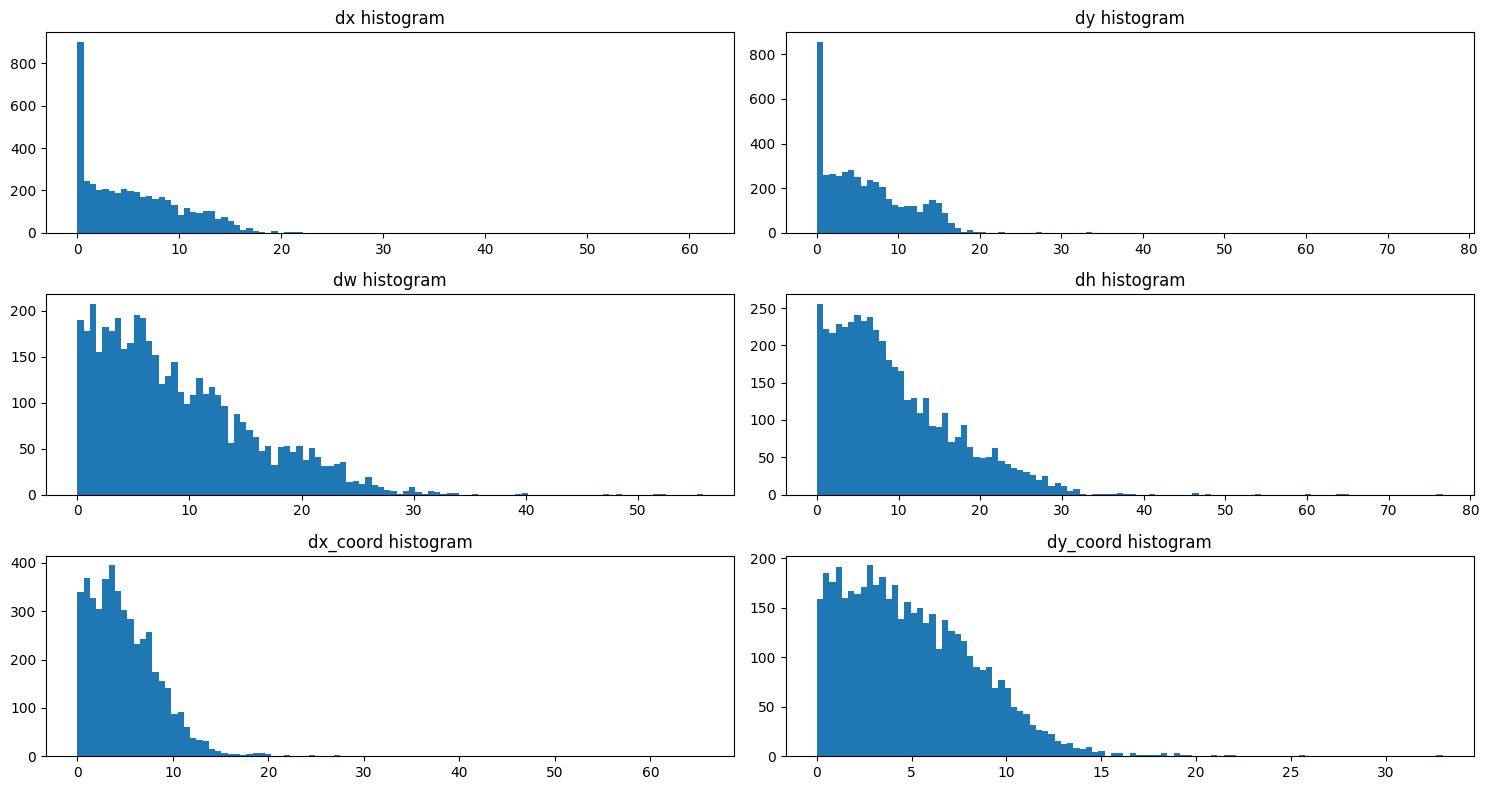

In [4]:
coord_dif = np.abs(buf_fp32_boxes - buf_uint8_boxes)
print("Coord dif mean:", coord_dif.mean(axis=0))
print("Coord dif std:", coord_dif.std(axis=0))
print("Coord dif median:", np.median(coord_dif, axis=0))
print("Coord dif max:", coord_dif.max(axis=0))

plt.figure(figsize=(15, 8))
plt.subplot(3, 2, 1)
plt.hist(coord_dif[:, 0].flatten(), bins=100)
plt.title('dx histogram')
plt.subplot(3, 2, 2)
plt.hist(coord_dif[:, 1].flatten(), bins=100)
plt.title('dy histogram')
plt.subplot(3, 2, 3)
plt.hist(coord_dif[:, 2].flatten(), bins=100)
plt.title('dw histogram')
plt.subplot(3, 2, 4)
plt.hist(coord_dif[:, 3].flatten(), bins=100)
plt.title('dh histogram')
plt.subplot(3, 2, 5)
plt.hist(coord_dif[:, 4].flatten(), bins=100)
plt.title('dx_coord histogram')
plt.subplot(3, 2, 6)
plt.hist(coord_dif[:, 5].flatten(), bins=100)
plt.title('dy_coord histogram')

plt.tight_layout()


In [5]:
for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression()
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores_stratified = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    break

In [6]:
# Train linear regression models for all 6 box coordinates
coord_names = ['dx', 'dy', 'dw', 'dh', 'dx_coord', 'dy_coord']
models = []

params = {}

# First: Train models on full dataset
for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression(fit_intercept=True)
    model.fit(X, y)
    models.append(model)
    
    print(f"{coord_names[i]}:")
    print(f"  Coef: {model.coef_[0]:.6f}, Intercept: {model.intercept_:.6f}")
    params[coord_names[i]] = {'coef': float(model.coef_[0]), 'intercept': float(model.intercept_)}

print("\n" + "="*50)
print("Model training completed\n")

# Second: Cross-validation evaluation
kf = KFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = []

for i in range(6):
    X = buf_uint8_boxes[:, i].reshape(-1, 1)
    y = buf_fp32_boxes[:, i]
    
    model = LinearRegression(fit_intercept=True)
    scores = cross_val_score(model, X, y, cv=kf, scoring='neg_mean_squared_error')
    cv_scores.append(scores)
    
    print(f"{coord_names[i]} - CV MSE: {-scores.mean():.4f} (+/- {scores.std():.4f})")

# MSE comparison: FP32 vs UINT8 (without regression)
print("\n" + "="*50)
print("MSE: FP32 vs UINT8 (direct conversion)\n")
mse_uint8 = mean_squared_error(buf_fp32_boxes, buf_uint8_boxes, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_uint8[i]:.4f}")
print(f"Overall MSE: {mse_uint8.mean():.4f}")

# MSE comparison: FP32 vs Regression predictions (UINT8 as input)
print("\n" + "="*50)
print("MSE: FP32 vs Regression predictions (UINT8 input)\n")
predictions = np.column_stack([models[i].predict(buf_uint8_boxes[:, i].reshape(-1, 1)) for i in range(6)])
mse_regression = mean_squared_error(buf_fp32_boxes, predictions, multioutput='raw_values')
for i, name in enumerate(coord_names):
    print(f"{name}: {mse_regression[i]:.4f}")
print(f"Overall MSE: {mse_regression.mean():.4f}")

# Improvement comparison
print("\n" + "="*50)
print("MSE Improvement (UINT8 -> Regression)\n")
for i, name in enumerate(coord_names):
    improvement = ((mse_uint8[i] - mse_regression[i]) / mse_uint8[i]) * 100
    print(f"{name}: {improvement:.2f}%")
print(f"Overall: {((mse_uint8.mean() - mse_regression.mean()) / mse_uint8.mean()) * 100:.2f}%")

with open('regression_params_nano.json', 'w') as f:
    json.dump(params, f, indent=4)
print("\nRegression parameters saved to 'regression_params_nano.json'")

dx:
  Coef: 0.990615, Intercept: 0.796890
dy:
  Coef: 0.984818, Intercept: 1.304268
dw:
  Coef: 0.751451, Intercept: 13.833393
dh:
  Coef: 0.580065, Intercept: 21.092894
dx_coord:
  Coef: 1.000768, Intercept: -1.260193
dy_coord:
  Coef: 0.995345, Intercept: 0.899979

Model training completed

dx - CV MSE: 58.6970 (+/- 7.8917)
dy - CV MSE: 65.2122 (+/- 5.0950)
dw - CV MSE: 99.1187 (+/- 6.9935)
dh - CV MSE: 77.3380 (+/- 5.4571)
dx_coord - CV MSE: 39.9233 (+/- 2.0056)
dy_coord - CV MSE: 36.4576 (+/- 1.1842)

MSE: FP32 vs UINT8 (direct conversion)

dx: 59.6869
dy: 66.2424
dw: 127.9321
dh: 145.4433
dx_coord: 41.1629
dy_coord: 36.6223
Overall MSE: 79.5150

MSE: FP32 vs Regression predictions (UINT8 input)

dx: 58.6170
dy: 65.1657
dw: 99.0602
dh: 77.1442
dx_coord: 39.8642
dy_coord: 36.4295
Overall MSE: 62.7135

MSE Improvement (UINT8 -> Regression)

dx: 1.79%
dy: 1.63%
dw: 22.57%
dh: 46.96%
dx_coord: 3.16%
dy_coord: 0.53%
Overall: 21.13%

Regression parameters saved to 'regression_params_nano